In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense

In [2]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel values normalized")

Pixel values normalized


In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print(class_names)

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax")
])

model.summary()

C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8244 - loss: 0.4994
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8648 - loss: 0.3762
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8760 - loss: 0.3376
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 8ms/step - accuracy: 0.8830 - loss: 0.3147
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8909 - loss: 0.2956


In [8]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Testing Accuracy:", accuracy)
print("Testing Accuracy (%):", accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8706 - loss: 0.3546
Testing Accuracy: 0.8705999851226807
Testing Accuracy (%): 87.05999851226807


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


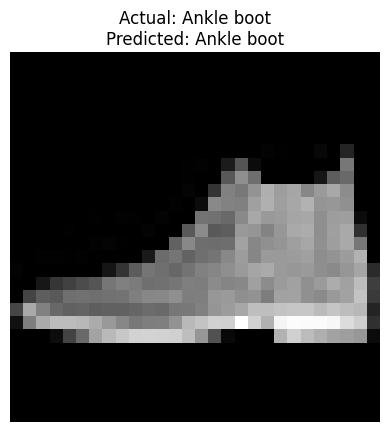

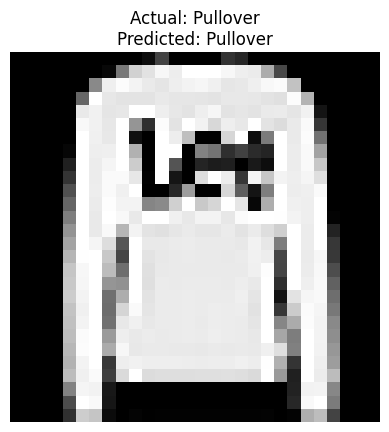

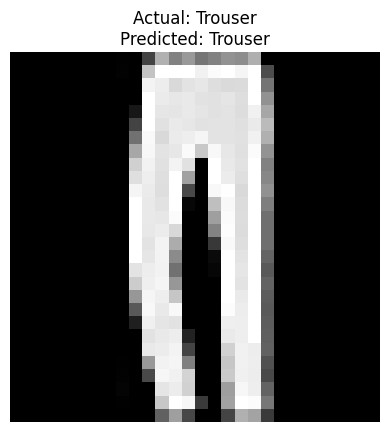

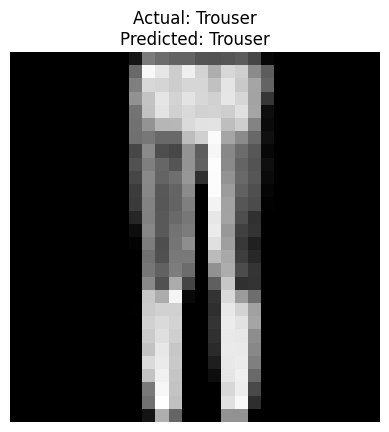

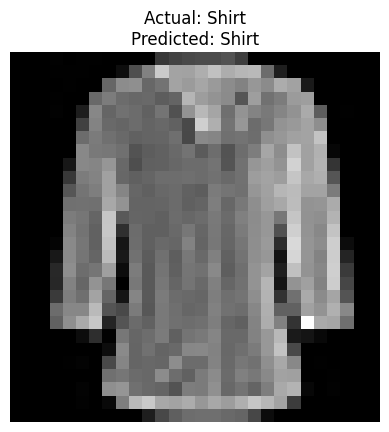

In [9]:
#cell for PS 11
predictions = model.predict(X_test)

for i in range(5):
    predicted = np.argmax(predictions[i])

    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        f"Actual: {class_names[y_test[i]]}\n"
        f"Predicted: {class_names[predicted]}"
    )
    plt.axis("off")
    plt.show()

In [ ]:
#here are the changes forthe chit 16

In [10]:
#for chit 16 confusion 
y_pred = np.argmax(
    model.predict(X_test),
    axis=1
)

print("Predictions completed")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predictions completed


In [11]:
from sklearn.metrics import confusion_matrix

In [12]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[843   0  20  10   3   0 118   1   5   0]
 [  3 970   0  19   3   0   3   0   2   0]
 [ 16   0 730  11 180   0  63   0   0   0]
 [ 31  12   7 865  40   0  41   0   4   0]
 [  0   1  54  34 849   0  61   0   1   0]
 [  0   0   0   1   0 970   0  11   0  18]
 [123   2  92  26  94   1 653   0   9   0]
 [  0   0   0   0   0  67   0 903   0  30]
 [  4   1   4   4   4   2   5   3 973   0]
 [  0   0   0   0   0   9   1  40   0 950]]


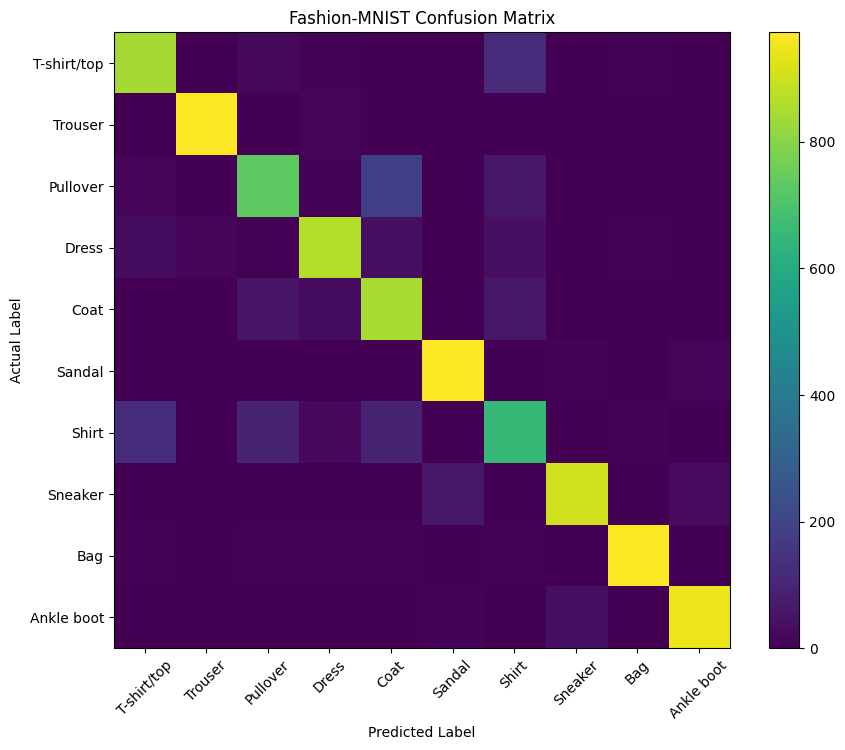

In [13]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fashion-MNIST Confusion Matrix")

plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.show()